In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn import tree
print(dir(tree))

['BaseDecisionTree', 'DecisionTreeClassifier', 'DecisionTreeRegressor', 'ExtraTreeClassifier', 'ExtraTreeRegressor', '__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', '_classes', '_criterion', '_export', '_partitioner', '_reingold_tilford', '_splitter', '_tree', '_utils', 'export_graphviz', 'export_text', 'plot_tree']


In [19]:
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score,classification_report,accuracy_score,confusion_matrix

In [4]:
df=pd.read_csv("Admission_Predict.csv")
print(df.head(5))

   Serial No.  GRE Score  TOEFL Score  University Rating  SOP  LOR   CGPA  \
0           1        337          118                  4  4.5   4.5  9.65   
1           2        324          107                  4  4.0   4.5  8.87   
2           3        316          104                  3  3.0   3.5  8.00   
3           4        322          110                  3  3.5   2.5  8.67   
4           5        314          103                  2  2.0   3.0  8.21   

   Research  Chance of Admit   
0         1              0.92  
1         1              0.76  
2         1              0.72  
3         1              0.80  
4         0              0.65  


In [13]:
df.dtypes

Serial No.             int64
GRE Score              int64
TOEFL Score            int64
University Rating      int64
SOP                  float64
LOR                  float64
CGPA                 float64
Research               int64
Chance of Admit      float64
dtype: object

In [15]:
df.columns=df.columns.str.strip()
df.dtypes

Serial No.             int64
GRE Score              int64
TOEFL Score            int64
University Rating      int64
SOP                  float64
LOR                  float64
CGPA                 float64
Research               int64
Chance of Admit      float64
dtype: object

In [16]:
df=df.drop(columns=['Serial No.'])

In [30]:
df['Admission Status']=(df['Chance of Admit']>=0.75).astype(int)

In [31]:
X=df.drop(columns=['Chance of Admit','Admission Status'])
y=df['Admission Status']

In [32]:
x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [33]:
model=DecisionTreeClassifier(criterion="gini",max_depth=5,random_state=42)

In [34]:
model.fit(x_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

In [36]:
y_pred=model.predict(x_test)

In [37]:
print("precision_score :",precision_score(y_test,y_pred))
print("classification_report :" ,classification_report(y_test,y_pred));
print(" accuracy_score: ",accuracy_score(y_test,y_pred))
cn=confusion_matrix(y_test,y_pred)
print(cn)

precision_score : 0.8108108108108109
classification_report :               precision    recall  f1-score   support

           0       0.93      0.85      0.89        47
           1       0.81      0.91      0.86        33

    accuracy                           0.88        80
   macro avg       0.87      0.88      0.87        80
weighted avg       0.88      0.88      0.88        80

 accuracy_score:  0.875
[[40  7]
 [ 3 30]]


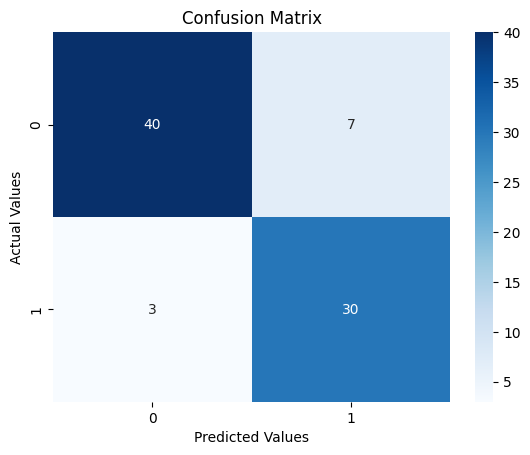

In [38]:
sns.heatmap(cn,cmap="Blues",annot=True,fmt='g',linecolor="white")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.title("Confusion Matrix")
plt.show()

In [40]:
help(plot_tree)

Help on function plot_tree in module sklearn.tree._export:

plot_tree(decision_tree, *, max_depth=None, feature_names=None, class_names=None, label='all', filled=False, impurity=True, node_ids=False, proportion=False, rounded=False, precision=3, ax=None, fontsize=None)
    Plot a decision tree.

    The sample counts that are shown are weighted with any sample_weights that
    might be present.

    The visualization is fit automatically to the size of the axis.
    Use the ``figsize`` or ``dpi`` arguments of ``plt.figure``  to control
    the size of the rendering.

    Read more in the :ref:`User Guide <tree>`.

    .. versionadded:: 0.21

    Parameters
    ----------
    decision_tree : decision tree regressor or classifier
        The decision tree to be plotted.

    max_depth : int, default=None
        The maximum depth of the representation. If None, the tree is fully
        generated.

    feature_names : array-like of str, default=None
        Names of each of the features.

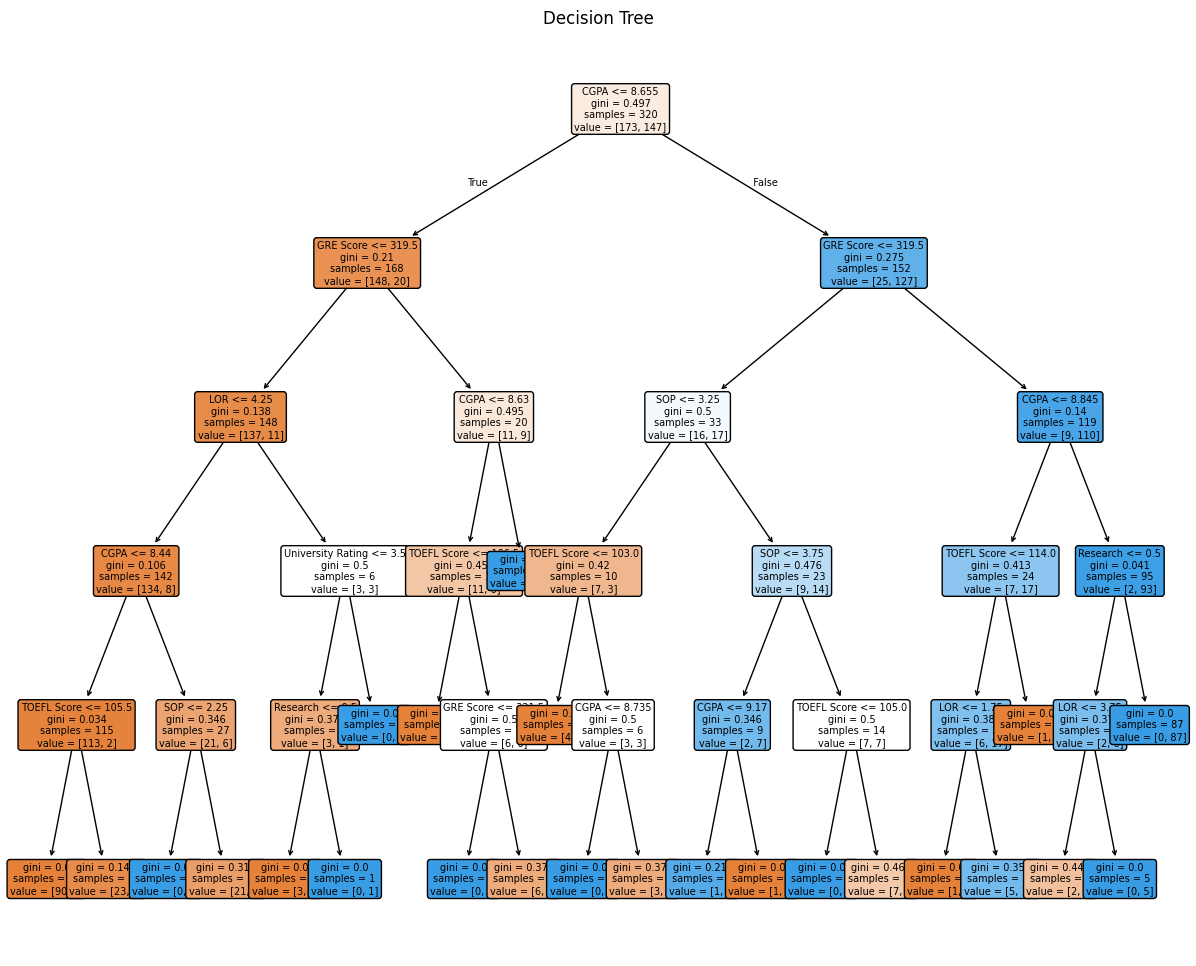

In [47]:
plt.figure(figsize=(15,12))
plot_tree(model,max_depth=5,feature_names=X.columns,filled=True,rounded=True,fontsize=7)
plt.title("Decision Tree")
plt.show()

In [48]:
# madfhantr.csv

df=pd.read_csv("loan.csv")
print(df.head(5))

    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001002   Male      No          0      Graduate            No   
1  LP001003   Male     Yes          1      Graduate            No   
2  LP001005   Male     Yes          0      Graduate           Yes   
3  LP001006   Male     Yes          0  Not Graduate            No   
4  LP001008   Male      No          0      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0         NaN             360.0   
1             4583             1508.0       128.0             360.0   
2             3000                0.0        66.0             360.0   
3             2583             2358.0       120.0             360.0   
4             6000                0.0       141.0             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Urban           Y  
1             1.0         Rural           N  
2             1.0   

In [49]:
# remove unnecessary col
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [51]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [52]:
# handle null value
df=df.dropna(subset=['Loan_Status'])

In [54]:
for col in df.columns:
    if df[col].dtypes=='object':
        df[col]=df[col].fillna(df[col].mode().iloc[0])
    else:
        df[col]=df[col].fillna(df[col].mean())

print(df.head(5))

    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001002   Male      No          0      Graduate            No   
1  LP001003   Male     Yes          1      Graduate            No   
2  LP001005   Male     Yes          0      Graduate           Yes   
3  LP001006   Male     Yes          0  Not Graduate            No   
4  LP001008   Male      No          0      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0  146.412162             360.0   
1             4583             1508.0  128.000000             360.0   
2             3000                0.0   66.000000             360.0   
3             2583             2358.0  120.000000             360.0   
4             6000                0.0  141.000000             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Urban           Y  
1             1.0         Rural           N  
2             1.0   

In [55]:
# remove loan id
df=df.drop('Loan_ID',axis=1)
print(df.head(5))

  Gender Married Dependents     Education Self_Employed  ApplicantIncome  \
0   Male      No          0      Graduate            No             5849   
1   Male     Yes          1      Graduate            No             4583   
2   Male     Yes          0      Graduate           Yes             3000   
3   Male     Yes          0  Not Graduate            No             2583   
4   Male      No          0      Graduate            No             6000   

   CoapplicantIncome  LoanAmount  Loan_Amount_Term  Credit_History  \
0                0.0  146.412162             360.0             1.0   
1             1508.0  128.000000             360.0             1.0   
2                0.0   66.000000             360.0             1.0   
3             2358.0  120.000000             360.0             1.0   
4                0.0  141.000000             360.0             1.0   

  Property_Area Loan_Status  
0         Urban           Y  
1         Rural           N  
2         Urban           Y  
3 

In [57]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()

In [58]:
df['Gender'].value_counts()

Gender
Male      502
Female    112
Name: count, dtype: int64

In [59]:
df['Gender']=df['Gender'].map({
    'Male':0,
    'Female':1
})

In [60]:
df.columns=df.columns.str.strip()

In [61]:
df['Education'].value_counts()

Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64

In [62]:
df['Education']=df['Education'].map({
    'Graduate':0,
    'Not Graduate':1
})

In [63]:
df['Property_Area']=le.fit_transform(df['Property_Area'])

In [64]:
df.head(5)

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,0,No,0,0,No,5849,0.0,146.412162,360.0,1.0,2,Y
1,0,Yes,1,0,No,4583,1508.0,128.000000,360.0,1.0,0,N
2,0,Yes,0,0,Yes,3000,0.0,66.000000,360.0,1.0,2,Y
3,0,Yes,0,1,No,2583,2358.0,120.000000,360.0,1.0,2,Y
4,0,No,0,0,No,6000,0.0,141.000000,360.0,1.0,2,Y


In [65]:
# map loan status
df['Loan_Status']=df['Loan_Status'].map({
    'Y':1,
    'N':0
})
df.head(5)

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,0,No,0,0,No,5849,0.0,146.412162,360.0,1.0,2,1
1,0,Yes,1,0,No,4583,1508.0,128.000000,360.0,1.0,0,0
2,0,Yes,0,0,Yes,3000,0.0,66.000000,360.0,1.0,2,1
3,0,Yes,0,1,No,2583,2358.0,120.000000,360.0,1.0,2,1
4,0,No,0,0,No,6000,0.0,141.000000,360.0,1.0,2,1


In [66]:
df['Self_Employed']=df['Self_Employed'].map({
    'Yes':1,
    'No':0
})
df.head(5)

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,0,No,0,0,0,5849,0.0,146.412162,360.0,1.0,2,1
1,0,Yes,1,0,0,4583,1508.0,128.000000,360.0,1.0,0,0
2,0,Yes,0,0,1,3000,0.0,66.000000,360.0,1.0,2,1
3,0,Yes,0,1,0,2583,2358.0,120.000000,360.0,1.0,2,1
4,0,No,0,0,0,6000,0.0,141.000000,360.0,1.0,2,1


In [67]:
df['Married']=df['Married'].map({
    'Yes':1,
    'No':0
})
df.head(5)

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,0,0,0,0,0,5849,0.0,146.412162,360.0,1.0,2,1
1,0,1,1,0,0,4583,1508.0,128.000000,360.0,1.0,0,0
2,0,1,0,0,1,3000,0.0,66.000000,360.0,1.0,2,1
3,0,1,0,1,0,2583,2358.0,120.000000,360.0,1.0,2,1
4,0,0,0,0,0,6000,0.0,141.000000,360.0,1.0,2,1


In [68]:
X=df.drop(columns=['Dependents','Loan_Status'])
y=df['Loan_Status']


x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [70]:
model=DecisionTreeClassifier(criterion="entropy",max_depth=4,random_state=42)

model.fit(x_train,y_train)

y_pred=model.predict(x_test)

In [71]:
print("precision_score :",precision_score(y_test,y_pred))
print("classification_report :" ,classification_report(y_test,y_pred));
print(" accuracy_score: ",accuracy_score(y_test,y_pred))
cn=confusion_matrix(y_test,y_pred)
print(cn)

precision_score : 0.75
classification_report :               precision    recall  f1-score   support

           0       0.78      0.42      0.55        43
           1       0.75      0.94      0.83        80

    accuracy                           0.76       123
   macro avg       0.77      0.68      0.69       123
weighted avg       0.76      0.76      0.73       123

 accuracy_score:  0.7560975609756098
[[18 25]
 [ 5 75]]


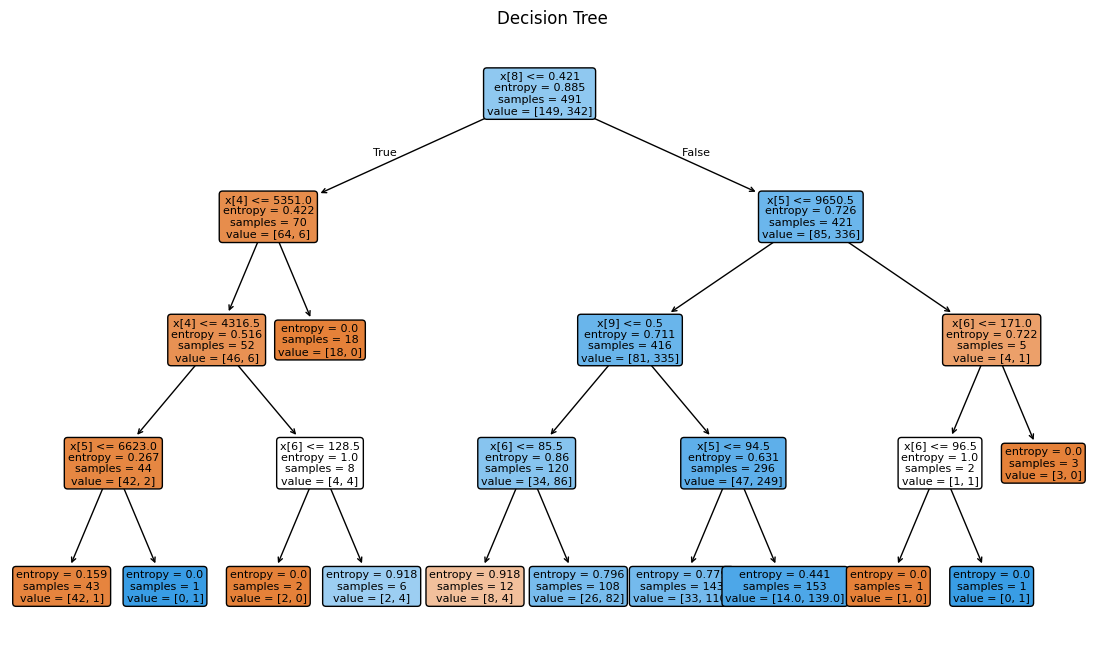

In [76]:
plt.figure(figsize=(14,8))
plot_tree(model,max_depth=4,rounded=True,filled=True,fontsize=8)
plt.title("Decision Tree")
plt.show()

In [78]:
# pima-indians-diabetes.csv


df=pd.read_csv("pima-indians-diabetes.csv",header=None)

df.columns=[ 'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age',
    'Outcome'
           ]
print(df.head(5))

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [79]:
df.dtypes

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

In [82]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [81]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [83]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [88]:
X=df.drop(columns=['Outcome'])
y=df['Outcome']

x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [89]:
model=DecisionTreeClassifier(criterion="entropy",max_depth=4,random_state=42)

model.fit(x_train,y_train)

y_pred=model.predict(x_test)

In [90]:
print("precision_score :",precision_score(y_test,y_pred))
print("classification_report :" ,classification_report(y_test,y_pred));
print(" accuracy_score: ",accuracy_score(y_test,y_pred))
cn=confusion_matrix(y_test,y_pred)
print(cn)

precision_score : 0.74
classification_report :               precision    recall  f1-score   support

           0       0.84      0.87      0.85       100
           1       0.74      0.69      0.71        54

    accuracy                           0.81       154
   macro avg       0.79      0.78      0.78       154
weighted avg       0.80      0.81      0.80       154

 accuracy_score:  0.8051948051948052
[[87 13]
 [17 37]]


In [92]:
# Heart.csv

df=pd.read_csv("Heart.csv")
print(df.head(5))

   Unnamed: 0  Age  Sex     ChestPain  RestBP  Chol  Fbs  RestECG  MaxHR  \
0           1   63    1       typical     145   233    1        2    150   
1           2   67    1  asymptomatic     160   286    0        2    108   
2           3   67    1  asymptomatic     120   229    0        2    129   
3           4   37    1    nonanginal     130   250    0        0    187   
4           5   41    0    nontypical     130   204    0        2    172   

   ExAng  Oldpeak  Slope   Ca        Thal  AHD  
0      0      2.3      3  0.0       fixed   No  
1      1      1.5      2  3.0      normal  Yes  
2      1      2.6      2  2.0  reversable  Yes  
3      0      3.5      3  0.0      normal   No  
4      0      1.4      1  0.0      normal   No  


In [94]:
df=df.drop('Unnamed: 0',axis=1)

In [99]:
print(df.head(5))

   Age  Sex  RestBP  Chol  Fbs  RestECG  MaxHR  ExAng  Oldpeak  Slope   Ca  \
0   63    1     145   233    1        2    150      0      2.3      3  0.0   
1   67    1     160   286    0        2    108      1      1.5      2  3.0   
2   67    1     120   229    0        2    129      1      2.6      2  2.0   
3   37    1     130   250    0        0    187      0      3.5      3  0.0   
4   41    0     130   204    0        2    172      0      1.4      1  0.0   

   AHD  ChestPain_nonanginal  ChestPain_nontypical  ChestPain_typical  \
0    0                     0                     0                  1   
1    1                     0                     0                  0   
2    1                     0                     0                  0   
3    0                     1                     0                  0   
4    0                     0                     1                  0   

   Thal_normal  Thal_reversable  
0            0                0  
1            1          

In [96]:
df=pd.get_dummies(df,columns=['ChestPain','Thal'],drop_first=True,dtype='int')

In [98]:
df['AHD']=df['AHD'].map({
    'No':0,
    'Yes':1
})

In [100]:
X=df.drop('AHD',axis=1)
y=df['AHD']

x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)


In [101]:
model=DecisionTreeClassifier(criterion="entropy",max_depth=4,random_state=42)

model.fit(x_train,y_train)

y_pred=model.predict(x_test)

In [102]:
print("precision_score :",precision_score(y_test,y_pred))
print("classification_report :" ,classification_report(y_test,y_pred));
print(" accuracy_score: ",accuracy_score(y_test,y_pred))
cn=confusion_matrix(y_test,y_pred)
print(cn)

precision_score : 0.7428571428571429
classification_report :               precision    recall  f1-score   support

           0       0.92      0.73      0.81        33
           1       0.74      0.93      0.83        28

    accuracy                           0.82        61
   macro avg       0.83      0.83      0.82        61
weighted avg       0.84      0.82      0.82        61

 accuracy_score:  0.819672131147541
[[24  9]
 [ 2 26]]
